# Red Agent v2 - tougher FGSM and PGD (evading the Blue Agent)

**Round 1 result:** the Blue Agent v1 caught 100% of the v1 attacks (99.2% 5-class accuracy, genuine-vs-attack AUC 1.0). It works because the v1 attacks leave clear fingerprints:

| v1 fingerprint | why it is easy to detect |
|---|---|
| L-infinity "sign" noise: almost every pixel moved by exactly +-8/255 | no camera produces such a uniform pattern |
| always the same strength (eps = 8/255) | the detector learned exactly that noise level |
| the attack ignores the detector | it only fools FaceNet and never tries to look clean |

**Round 2 (this notebook):** the **same two attacks, FGSM and PGD**, made harder to detect with three techniques - no new attack types:

| technique | what changes | which fingerprint it hides |
|---|---|---|
| `low_eps` | L-infinity attack with a random strength per image: 2, 4, 6 or 8 / 255 | "always 8/255" |
| `l2` | L2 version of FGSM / PGD: noise concentrated where it matters instead of +-8 on every pixel | the uniform sign pattern |
| `adaptive` | **detector-aware**: every step fools FaceNet **and** pushes the Blue Agent v1 towards "genuine" | all of them - the attacker knows the defence |

**Fair comparison with v1:** no pixel moves more than **8/255** in any technique (the L2 noise is also clipped to 8/255), images are saved as 8-bit PNG exactly like v1, and the attacked faces are the **same 500 genuine faces** as v1 (plus 500 new GAN faces for `gan_adv`). Each attacked image gets **one** technique, about 1/3 each.

**Key outputs:**
- how often each technique still fools the face model (attack strength), and
- how often the **Blue Agent v1 misses it** (stealth) - and the **full bypass rate**: face model fooled **and** Blue Agent says genuine.

Needs (inside `celeba/`): `red_agent_samples/` (v1), `identity_head.pth` + `head_identities.csv` (the v1 attack target), `generator_dcgan_50ep.pth`, `blue_agent/blue_agent_resnet18.pth` + `blue_agent/split.csv` (Blue Agent v1). Output: `celeba/red_agent_samples_v2/`.

### 0. setup

In [1]:
import os, time, shutil
os.chdir("/workspace")
print("working directory:", os.getcwd())

try:
    import art
except ImportError:
    raise ImportError("ART is not installed on this machine - run: bash /workspace/install.sh")
print("ART version:", art.__version__)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from facenet_pytorch import InceptionResnetV1
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import FastGradientMethod, ProjectedGradientDescent

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)

working directory: /workspace
ART version: 1.20.1
device: cuda | NVIDIA RTX PRO 6000 Blackwell Server Edition MIG 1g.24gb


In [2]:
BASE = "./celeba"
V1_DIR = os.path.join(BASE, "red_agent_samples")
OUT_DIR = os.path.join(BASE, "red_agent_samples_v2")
GEN_PATH = os.path.join(BASE, "generator_dcgan_50ep.pth")
HEAD_PATH = os.path.join(BASE, "identity_head.pth")
HEAD_IDS = os.path.join(BASE, "head_identities.csv")
BLUE_PATH = os.path.join(BASE, "blue_agent", "blue_agent_resnet18.pth")
SPLIT_PATH = os.path.join(BASE, "blue_agent", "split.csv")
for p in [V1_DIR, GEN_PATH, HEAD_PATH, HEAD_IDS, BLUE_PATH, SPLIT_PATH]:
    assert os.path.exists(p), f"missing: {p}"

EPS_MAX = 2 * 8 / 255                 # 8/255 in pixel space = 0.0627 in the [-1, 1] range (same budget as v1)
LOW_EPS_255 = [2, 4, 6, 8]            # technique low_eps: strength drawn per image
L2_EPS_01 = [1.0, 2.0, 3.0]           # technique l2: L2 budget in [0, 1] pixel units, drawn per image (then clipped to 8/255)
ADV_STEPS = 50                        # technique adaptive (PGD): more steps, it has two goals to satisfy
ADV_KAPPA = 5.0                       # adaptive: stop pushing FaceNet once the wrong identity leads by this logit margin
ADV_LAMBDA = 1.0                      # adaptive: weight of "look genuine to the Blue Agent"
N_GAN_ADV = 500
BATCH = 16
TECHNIQUES = ["low_eps", "l2", "adaptive"]

### 1. rebuild the v1 attack target (FaceNet + the saved 300-identity head)
The same frozen FaceNet and the identity head saved by the v1 notebook, so v2 attacks the exact same face-recognition model. Sanity check: the v1 genuine faces were chosen because the model recognised them, so accuracy on them must be ~100%.

In [3]:
ids = pd.read_csv(HEAD_IDS)["identity"].to_numpy()
N_ID = len(ids)
id_to_idx = {int(i): k for k, i in enumerate(ids)}
idx_to_id = {k: int(i) for i, k in id_to_idx.items()}

backbone = InceptionResnetV1(pretrained="vggface2").eval().to(device)
head = nn.Linear(512, N_ID).to(device)
head.load_state_dict(torch.load(HEAD_PATH, map_location=device, weights_only=True))
for p in list(backbone.parameters()) + list(head.parameters()):
    p.requires_grad = False

class FaceClassifier(nn.Module):
    def __init__(self, backbone, head):
        super().__init__()
        self.backbone, self.head = backbone, head
    def forward(self, x):                               # x in [-1, 1]
        return self.head(self.backbone(x))

face = FaceClassifier(backbone, head).eval().to(device)
classifier = PyTorchClassifier(model=face, loss=nn.CrossEntropyLoss(), input_shape=(3, 160, 160),
                               nb_classes=N_ID, clip_values=(-1.0, 1.0),
                               device_type="gpu" if device.type == "cuda" else "cpu")

def quantize(x):
    return np.round((x * 0.5 + 0.5) * 255).clip(0, 255).astype(np.uint8)

def dequantize(u):
    return (u.astype(np.float32) / 255 - 0.5) / 0.5

def load_png(path):
    a = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
    return ((a - 0.5) / 0.5).transpose(2, 0, 1)

v1 = pd.read_csv(os.path.join(V1_DIR, "labels.csv"))
gen = v1[v1["category"] == "genuine"].reset_index(drop=True)
x_gen = np.stack([load_png(os.path.join(V1_DIR, "genuine", f)) for f in gen["file_name"]])
y_gen = gen["identity"].map(id_to_idx).to_numpy()
assert not np.isnan(y_gen.astype(float)).any(), "a genuine identity is not in head_identities.csv"
y_gen = y_gen.astype(int)

acc = (classifier.predict(x_gen, batch_size=BATCH).argmax(1) == y_gen).mean()
print(f"attack target rebuilt: {N_ID} identities | accuracy on the {len(x_gen)} v1 genuine faces: {acc:.1%}")

attack target rebuilt: 300 identities | accuracy on the 500 v1 genuine faces: 100.0%


### 2. load the Blue Agent v1 (the detector to evade)
Wrapped so it takes the same `[-1, 1]` images as FaceNet; inside it converts to `[0, 1]` and applies the ImageNet normalisation it was trained with. Sanity check: it should call the v1 genuine faces genuine and the v1 attacks attacks.

In [4]:
ckpt = torch.load(BLUE_PATH, map_location=device, weights_only=True)
BLUE_CLASSES = ckpt["classes"]
GENUINE = BLUE_CLASSES.index("genuine")
resnet = torchvision.models.resnet18(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, len(BLUE_CLASSES))
resnet.load_state_dict(ckpt["state_dict"])

class BlueOnFaceRange(nn.Module):
    def __init__(self, net, mean, std):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))
    def forward(self, x):                               # x in [-1, 1]
        return self.net(((x + 1) / 2 - self.mean) / self.std)

blue = BlueOnFaceRange(resnet, ckpt["mean"], ckpt["std"]).eval().to(device)
for p in blue.parameters():
    p.requires_grad = False

@torch.no_grad()
def blue_probs(x):
    out = []
    for i in range(0, len(x), 64):
        out.append(torch.softmax(blue(torch.from_numpy(x[i:i + 64]).to(device)), 1).cpu())
    return torch.cat(out).numpy()

p = blue_probs(x_gen)
print(f"Blue Agent v1 loaded | classes {BLUE_CLASSES} | v1 genuine faces called genuine: {(p.argmax(1) == GENUINE).mean():.1%}")

Blue Agent v1 loaded | classes ['genuine', 'gan', 'fgsm', 'pgd', 'gan_adv'] | v1 genuine faces called genuine: 100.0%


### 3. base images and technique assignment
- **person-based attacks** (`fgsm`, `pgd`): the same 500 genuine faces as v1. Each face is attacked once with FGSM and once with PGD, each time with one randomly assigned technique (~1/3 each).
- **`gan_adv`**: 500 **new** GAN faces (own seed, different from v1's `gan` and `gan_adv`), 250 FGSM-based + 250 PGD-based, again ~1/3 per technique; the reference identity is the person each GAN face currently matches best (untargeted, like v1).
- the Blue Agent v1 person split (`split.csv`) is carried over, so a test-split person stays in the test split when the Blue Agent v2 is trained.

In [5]:
rng = np.random.default_rng(SEED + 10)

def assign(n):
    t = np.array([TECHNIQUES[i % 3] for i in range(n)])
    rng.shuffle(t)
    eps = np.where(t == "low_eps", rng.choice(LOW_EPS_255, n), 8).astype(float)    # eps in /255 (L-infinity)
    l2 = np.where(t == "l2", rng.choice(L2_EPS_01, n), np.nan)                      # L2 budget in [0, 1] units
    return t, eps, l2

tech_fgsm, eps_fgsm, l2_fgsm = assign(len(x_gen))
tech_pgd, eps_pgd, l2_pgd = assign(len(x_gen))

# new GAN faces
class Generator(nn.Module):
    def __init__(self, noise_dim=100, feature_maps=64):
        super().__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(noise_dim, feature_maps * 8, 4, 1, 0, bias=False), nn.BatchNorm2d(feature_maps * 8), nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps * 8, feature_maps * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(feature_maps * 4), nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps * 4, feature_maps * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(feature_maps * 2), nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps * 2, feature_maps, 4, 2, 1, bias=False), nn.BatchNorm2d(feature_maps), nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps, 3, 4, 2, 1, bias=False), nn.Tanh())
    def forward(self, x):
        return self.main(x)

generator = Generator(100).to(device)
generator.load_state_dict(torch.load(GEN_PATH, map_location=device, weights_only=True))
generator.eval()
g = torch.Generator(device=device).manual_seed(SEED + 2)       # own seed: not the v1 gan / gan_adv faces
with torch.no_grad():
    z = torch.randn(N_GAN_ADV, 100, 1, 1, device=device, generator=g)
    x_gan = F.interpolate(generator(z), size=160, mode="bilinear", align_corners=False).clamp(-1, 1).cpu().numpy()
x_gan = dequantize(quantize(x_gan.astype(np.float32)))         # the 8-bit image a saved GAN PNG holds
y_gan = classifier.predict(x_gan, batch_size=BATCH).argmax(1)
half = N_GAN_ADV // 2
gan_attack = np.array(["fgsm"] * half + ["pgd"] * (N_GAN_ADV - half))
tech_gan, eps_gan, l2_gan = assign(N_GAN_ADV)

split_v1 = pd.read_csv(SPLIT_PATH)
id_split = split_v1[split_v1["category"] == "genuine"].drop_duplicates("identity").set_index("identity")["split"]
gen_split = gen["identity"].map(id_split).to_numpy()

print("genuine bases:", x_gen.shape, "| new GAN bases:", x_gan.shape)
print("technique counts (fgsm / pgd / gan_adv):",
      pd.Series(tech_fgsm).value_counts().to_dict(), pd.Series(tech_pgd).value_counts().to_dict(),
      pd.Series(tech_gan).value_counts().to_dict())
print("low_eps strengths used (/255):", sorted(set(eps_fgsm[tech_fgsm == "low_eps"].astype(int))))
print("v1 split carried over for genuine faces:", pd.Series(gen_split).value_counts().to_dict())

genuine bases: (500, 3, 160, 160) | new GAN bases: (500, 3, 160, 160)
technique counts (fgsm / pgd / gan_adv): {'low_eps': 167, 'l2': 167, 'adaptive': 166} {'low_eps': 167, 'l2': 167, 'adaptive': 166} {'low_eps': 167, 'l2': 167, 'adaptive': 166}
low_eps strengths used (/255): [np.int64(2), np.int64(4), np.int64(6), np.int64(8)]
v1 split carried over for genuine faces: {'train': 355, 'test': 73, 'val': 72}


### 4. the three techniques
- `low_eps` and `l2` use ART, exactly like v1 (`FastGradientMethod` / `ProjectedGradientDescent`), only with a different strength or `norm=2`. The L2 noise is then clipped to +-8/255 so no pixel exceeds the v1 budget.
- `adaptive` is written by hand because ART has no "fool two models at once" attack. Each step climbs one combined objective:

  `objective = min(margin_face, kappa) - lambda * CE(BlueAgent(x), genuine)`

  - `margin_face` = best wrong identity logit - true identity logit: positive means FaceNet is fooled. It is capped at `kappa`, so once FaceNet is fooled with a safe margin all the effort goes into hiding from the Blue Agent.
  - `CE(BlueAgent(x), genuine)` is small when the Blue Agent believes the image is genuine.
  - **adaptive FGSM** = one step of size 8/255 on this objective; **adaptive PGD** = 50 steps of 8/255 / 10 with a random start, keeping the best iterate that fools both models.

In [6]:
def art_attack(attack, x, y, norm, budget):
    # one ART call per budget value; budget = eps in /255 (L-inf) or L2 budget in [0, 1] units
    out = np.empty_like(x)
    yo = np.eye(N_ID, dtype=np.float32)[y]
    for b in np.unique(budget):
        m = budget == b
        if norm == np.inf:
            e = 2 * b / 255
        else:
            e = 2 * b                                   # [0, 1] units -> [-1, 1] units
        if attack == "fgsm":
            a = FastGradientMethod(classifier, norm=norm, eps=e, batch_size=BATCH)
        else:
            a = ProjectedGradientDescent(classifier, norm=norm, eps=e, eps_step=e / 8, max_iter=20,
                                         num_random_init=1, batch_size=BATCH, verbose=False)
        out[m] = a.generate(x=x[m], y=yo[m])
    return np.clip(out, np.clip(x - EPS_MAX, -1, 1), np.clip(x + EPS_MAX, -1, 1))   # 8/255 budget for every technique

def adaptive_objective(xa, y):
    z = face(xa)
    z_true = z.gather(1, y[:, None]).squeeze(1)
    z_other = z.masked_fill(F.one_hot(y, N_ID).bool(), -1e9).max(1).values
    margin = z_other - z_true                            # > 0  -> FaceNet fooled
    b = blue(xa)
    ce_gen = F.cross_entropy(b, torch.full_like(y, GENUINE), reduction="none")
    obj = margin.clamp(max=ADV_KAPPA) - ADV_LAMBDA * ce_gen
    success = (margin > 0) & (torch.softmax(b, 1)[:, GENUINE] > 0.5)   # FaceNet fooled AND Blue attack prob < 0.5
    return obj, success

def adaptive_attack(x, y, attack, eps=EPS_MAX):
    out = np.empty_like(x)
    for i in range(0, len(x), BATCH):
        x0 = torch.from_numpy(x[i:i + BATCH]).to(device)
        yy = torch.from_numpy(y[i:i + BATCH]).long().to(device)
        if attack == "fgsm":
            xa = x0.clone().requires_grad_(True)
            obj, _ = adaptive_objective(xa, yy)
            grad, = torch.autograd.grad(obj.sum(), xa)
            best = (x0 + eps * grad.sign()).clamp(-1, 1).detach()
        else:
            step = eps / 10
            xa = (x0 + torch.empty_like(x0).uniform_(-eps, eps)).clamp(-1, 1)
            best, best_ok = xa.clone(), torch.zeros(len(x0), dtype=torch.bool, device=device)
            for _ in range(ADV_STEPS):
                xa.requires_grad_(True)
                obj, ok = adaptive_objective(xa, yy)
                grad, = torch.autograd.grad(obj.sum(), xa)
                with torch.no_grad():
                    newly = ok & ~best_ok                       # keep the first iterate that fools both models
                    best[newly] = xa.detach()[newly]; best_ok |= ok
                    xa = xa.detach() + step * grad.sign()
                    xa = torch.max(torch.min(xa, x0 + eps), x0 - eps).clamp(-1, 1)
            with torch.no_grad():
                best[~best_ok] = xa[~best_ok]                   # never succeeded: keep the last iterate
        out[i:i + BATCH] = best.cpu().numpy()
    return out

def run_attack(x, y, attack, tech, eps255, l2):
    out = np.empty_like(x)
    m = tech == "low_eps"
    if m.any():
        out[m] = art_attack(attack, x[m], y[m], np.inf, eps255[m])
    m = tech == "l2"
    if m.any():
        out[m] = art_attack(attack, x[m], y[m], 2, l2[m])
    m = tech == "adaptive"
    if m.any():
        out[m] = adaptive_attack(x[m], y[m], attack)
    return dequantize(quantize(out))                    # saved as 8-bit PNG, evaluate what survives the rounding

t0 = time.time()
x_fgsm2 = run_attack(x_gen, y_gen, "fgsm", tech_fgsm, eps_fgsm, l2_fgsm); print(f"fgsm v2 done   {time.time() - t0:.0f}s")
x_pgd2 = run_attack(x_gen, y_gen, "pgd", tech_pgd, eps_pgd, l2_pgd);      print(f"pgd v2 done    {time.time() - t0:.0f}s")
x_ganadv2 = np.empty_like(x_gan)
for att in ["fgsm", "pgd"]:
    m = gan_attack == att
    x_ganadv2[m] = run_attack(x_gan[m], y_gan[m], att, tech_gan[m], eps_gan[m], l2_gan[m])
print(f"gan_adv v2 done {time.time() - t0:.0f}s")

fgsm v2 done   7s
pgd v2 done    176s
gan_adv v2 done 269s


### 5. results: attack strength vs stealth
For each attack and technique:
- `face_fooled`: share of images FaceNet no longer matches to the right person (attack strength)
- `face_conf`: FaceNet's confidence in its (wrong) answer
- `blue_detected`: share the Blue Agent v1 flags as an attack (attack probability = 1 - P(genuine) >= 0.5, the same rule as the Blue Agent notebook)
- **`full_bypass`**: FaceNet fooled **and** the Blue Agent v1 does **not** flag it - the attacker gets through both layers
- `linf_255` / `l2_01`: real perturbation size after 8-bit rounding (max pixel change in /255, L2 in [0, 1] units)

The v1 rows are the baseline from round 1. `test persons only` repeats the person-based rows on faces whose person is in the Blue Agent v1 **test** split (never seen in its training).

In [7]:
def score(name, tech, x, y, x_ref, mask=None):
    if mask is not None:
        x, y, x_ref = x[mask], y[mask], x_ref[mask]
    if len(x) == 0:
        return None
    logits = classifier.predict(x, batch_size=BATCH)
    pf = torch.softmax(torch.from_numpy(logits), 1).numpy()
    fooled = logits.argmax(1) != y
    pb = blue_probs(x)
    detected = 1 - pb[:, GENUINE] >= 0.5
    d = (x - x_ref) * 0.5
    return {"attack": name, "technique": tech, "images": len(x),
            "face_fooled": fooled.mean(), "face_conf": pf.max(1).mean(),
            "blue_detected": detected.mean(), "full_bypass": (fooled & ~detected).mean(),
            "linf_255": np.abs(d).max(axis=(1, 2, 3)).mean() * 255, "l2_01": np.sqrt((d ** 2).sum(axis=(1, 2, 3))).mean()}

# round-1 baseline: the saved v1 attacks
def load_v1(cat):
    sub = v1[v1["category"] == cat]
    return np.stack([load_png(os.path.join(V1_DIR, cat, f)) for f in sub["file_name"]]), sub
x_fgsm1, s1 = load_v1("fgsm"); x_pgd1, _ = load_v1("pgd")
y_v1 = s1["identity"].map(id_to_idx).to_numpy().astype(int)
x_gen_v1order = np.stack([load_png(os.path.join(V1_DIR, "genuine", f)) for f in s1["file_name"]])

rows = [score("fgsm", "v1 (round 1)", x_fgsm1, y_v1, x_gen_v1order),
        score("pgd", "v1 (round 1)", x_pgd1, y_v1, x_gen_v1order)]
for name, x2, tech in [("fgsm", x_fgsm2, tech_fgsm), ("pgd", x_pgd2, tech_pgd)]:
    for t in TECHNIQUES:
        rows.append(score(name, t, x2, y_gen, x_gen, tech == t))
for att in ["fgsm", "pgd"]:
    for t in TECHNIQUES:
        rows.append(score(f"gan_adv ({att})", t, x_ganadv2, y_gan, x_gan, (gan_attack == att) & (tech_gan == t)))
results = pd.DataFrame([r for r in rows if r is not None])
print(results.round(3).to_string(index=False))

test_m = gen_split == "test"
rows_t = []
for name, x2, tech in [("fgsm", x_fgsm2, tech_fgsm), ("pgd", x_pgd2, tech_pgd)]:
    for t in TECHNIQUES:
        rows_t.append(score(name, t, x2, y_gen, x_gen, (tech == t) & test_m))
results_test = pd.DataFrame([r for r in rows_t if r is not None])
print("\ntest persons only (never seen by the Blue Agent v1):")
print(results_test.round(3).to_string(index=False))

        attack    technique  images  face_fooled  face_conf  blue_detected  full_bypass  linf_255  l2_01
          fgsm v1 (round 1)     500        0.992      0.626          1.000        0.000     8.000  8.426
           pgd v1 (round 1)     500        1.000      0.988          1.000        0.000     8.000  6.471
          fgsm      low_eps     167        0.898      0.630          0.623        0.287     4.647  4.906
          fgsm           l2     167        0.802      0.654          0.000        0.802     8.000  1.760
          fgsm     adaptive     166        0.994      0.953          1.000        0.000     8.000  8.581
           pgd      low_eps     167        0.988      0.978          0.701        0.287     5.389  4.593
           pgd           l2     167        0.970      0.951          0.000        0.970     8.000  1.882
           pgd     adaptive     166        1.000      0.764          0.000        1.000     8.000  5.029
gan_adv (fgsm)      low_eps      93        1.000      0

average over fgsm / pgd / gan_adv:
              face_fooled  blue_detected  full_bypass
technique                                            
v1 (round 1)        0.996          1.000        0.000
low_eps             0.972          0.831        0.144
l2                  0.943          0.497        0.446
adaptive            0.995          0.500        0.500


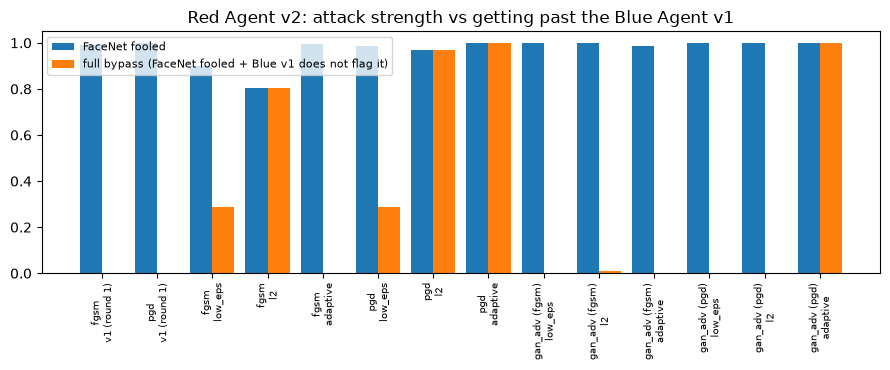

In [8]:
# headline: how much stealthier did the Red Agent get?
summary = results.groupby("technique", sort=False)[["face_fooled", "blue_detected", "full_bypass"]].mean()
print("average over fgsm / pgd / gan_adv:")
print(summary.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.8))
lab = [f"{a}\n{t}" for a, t in zip(results["attack"], results["technique"])]
xs = np.arange(len(results))
ax.bar(xs - 0.2, results["face_fooled"], 0.4, label="FaceNet fooled")
ax.bar(xs + 0.2, results["full_bypass"], 0.4, label="full bypass (FaceNet fooled + Blue v1 does not flag it)")
ax.set_xticks(xs, lab, rotation=90, fontsize=7); ax.set_ylim(0, 1.05); ax.legend(fontsize=8)
ax.set_title("Red Agent v2: attack strength vs getting past the Blue Agent v1")
plt.tight_layout(); plt.savefig(os.path.join(BASE, "red_agent_v2_results.png"), dpi=120); plt.show()

### 6. what the new attacks look like
For each technique: original | attacked | perturbation x10. Compare with v1: the `l2` and `adaptive` noise should look less like a uniform +-8 grid.

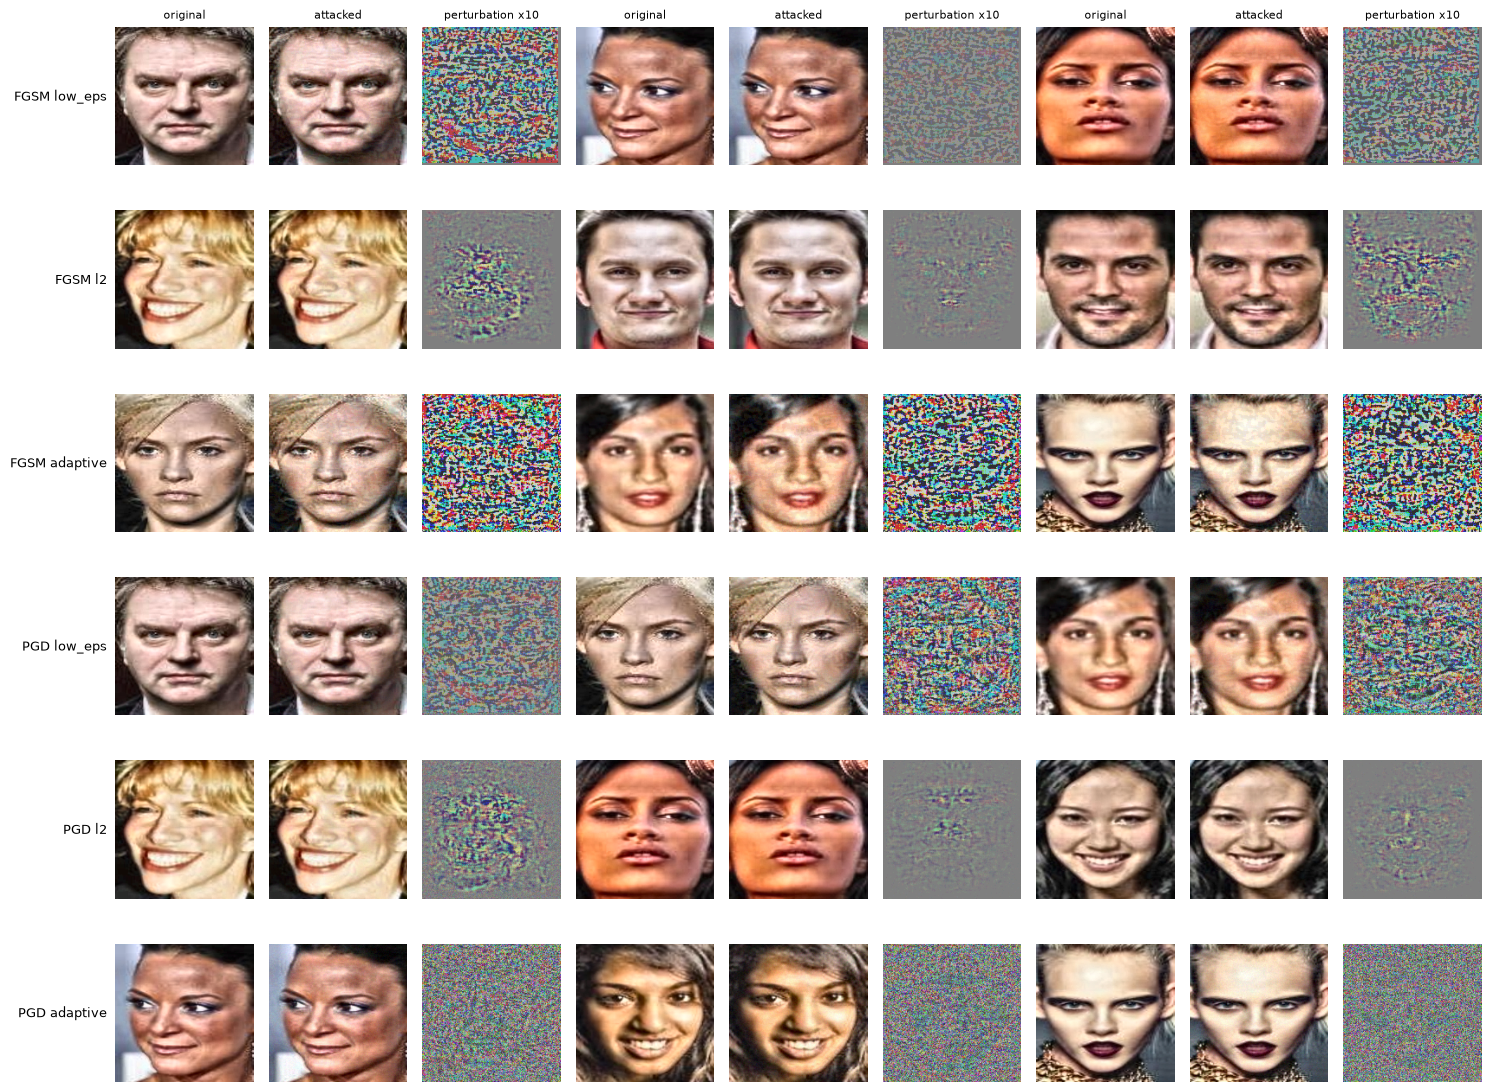

In [9]:
def show(x):
    return (x * 0.5 + 0.5).clip(0, 1).transpose(1, 2, 0)

panels = []
for name, x2, tech in [("FGSM", x_fgsm2, tech_fgsm), ("PGD", x_pgd2, tech_pgd)]:
    for t in TECHNIQUES:
        panels.append((f"{name} {t}", x2, np.where(tech == t)[0][:3]))
fig, axes = plt.subplots(len(panels), 9, figsize=(15, 1.9 * len(panels)), squeeze=False)
for r, (name, x2, idx) in enumerate(panels):
    for k, i in enumerate(idx):
        trio = [show(x_gen[i]), show(x2[i]), ((x2[i] - x_gen[i]) * 10 * 0.5 + 0.5).clip(0, 1).transpose(1, 2, 0)]
        for j, im in enumerate(trio):
            a = axes[r, 3 * k + j]; a.imshow(im); a.axis("off")
            if r == 0:
                a.set_title(["original", "attacked", "perturbation x10"][j], fontsize=8)
    axes[r, 0].text(-10, 80, name, fontsize=9, ha="right", va="center")
    for a in axes[r, 3 * len(idx):]:
        a.axis("off")
plt.tight_layout(); plt.show()

### 7. save the v2 dataset
Same layout as v1 (`fgsm/`, `pgd/`, `gan_adv/` + `labels.csv`) in `celeba/red_agent_samples_v2/`. `labels.csv` adds `technique`, `eps_255`, `l2_budget`, the measured perturbation, whether FaceNet was fooled, the Blue Agent v1 verdict and `split_v1` (the v1 person split for person-based images). `genuine` and `gan` are not duplicated - the Blue Agent v2 reuses them from v1.

In [10]:
for cat in ["fgsm", "pgd", "gan_adv"]:
    os.makedirs(os.path.join(OUT_DIR, cat), exist_ok=True)

def save(cat, x, x_ref, y, tech, eps255, l2, names, identity, attack, split):
    u = quantize(x).transpose(0, 2, 3, 1)
    logits = classifier.predict(x, batch_size=BATCH)
    pf = torch.softmax(torch.from_numpy(logits), 1).numpy()
    pb = blue_probs(x)
    d = (x - x_ref) * 0.5
    out = []
    for k in range(len(u)):
        Image.fromarray(u[k]).save(os.path.join(OUT_DIR, cat, names[k]))
        out.append({"category": cat, "file_name": names[k], "identity": identity[k],
                    "pred_identity": idx_to_id[int(logits[k].argmax())], "confidence": float(pf[k].max()),
                    "attack": attack[k], "technique": tech[k], "eps_255": float(eps255[k]) if tech[k] != "l2" else 8.0,
                    "l2_budget": float(l2[k]) if tech[k] == "l2" else np.nan,
                    "linf_255": float(np.abs(d[k]).max() * 255), "l2_01": float(np.sqrt((d[k] ** 2).sum())),
                    "face_fooled": bool(logits[k].argmax() != y[k]),
                    "blue_v1_pred": BLUE_CLASSES[int(pb[k].argmax())], "blue_v1_attack_prob": float(1 - pb[k, GENUINE]),
                    "split_v1": split[k]})
    return out

n = len(x_gen)
manifest = (save("fgsm", x_fgsm2, x_gen, y_gen, tech_fgsm, eps_fgsm, l2_fgsm, list(gen["file_name"]),
                 list(gen["identity"]), ["fgsm"] * n, list(gen_split))
            + save("pgd", x_pgd2, x_gen, y_gen, tech_pgd, eps_pgd, l2_pgd, list(gen["file_name"]),
                   list(gen["identity"]), ["pgd"] * n, list(gen_split))
            + save("gan_adv", x_ganadv2, x_gan, y_gan, tech_gan, eps_gan, l2_gan,
                   [f"ganadv2_{a}_{t}_{k:03d}.png" for k, (a, t) in enumerate(zip(gan_attack, tech_gan))],
                   [-1] * N_GAN_ADV, list(gan_attack), [""] * N_GAN_ADV))
labels2 = pd.DataFrame(manifest)
labels2.to_csv(os.path.join(OUT_DIR, "labels.csv"), index=False)
results.to_csv(os.path.join(OUT_DIR, "results.csv"), index=False)
results_test.to_csv(os.path.join(OUT_DIR, "results_test_persons.csv"), index=False)

zip_path = shutil.make_archive(os.path.join(BASE, "red_agent_samples_v2"), "zip", OUT_DIR)
print("saved", len(labels2), "images to", OUT_DIR, "| zip:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.0f} MB)")
print(pd.crosstab(labels2["category"], labels2["technique"]).to_string())

saved 1500 images to ./celeba/red_agent_samples_v2 | zip: /workspace/celeba/red_agent_samples_v2.zip (71 MB)
technique  adaptive   l2  low_eps
category                         
fgsm            166  167      167
gan_adv         166  167      167
pgd             166  167      167


### milestone check
- same FGSM / PGD attacks, made stealthier with 3 techniques (mixed strength, L2, detector-aware), all within the v1 budget of 8/255
- `results.csv`: per technique, how often FaceNet is still fooled and how often the Blue Agent v1 is bypassed
- `red_agent_samples_v2/` (1,500 images) + `labels.csv` ready for the Blue Agent v2 (next notebook: `blue_agent/BlueAgent_v2.ipynb`)